# 04. TabPFN 재현 — 논문 수치로 학습하고 Table 1과 비교

[`01_scm_primer`](01_scm_primer.ipynb)와 [`02_bnn_primer`](02_bnn_primer.ipynb)에서는 prior를 단순화해서 봤습니다. 이 노트북은 논문과 공식 v1 코드의 실제 수치로 TabPFN을 학습한 결과를 정리합니다.

재현 판정 기준은 논문 Table 1입니다. OpenML-CC18 중 수치형 feature만 있고 결측값이 없는 18개 데이터셋에서, 데이터셋마다 split 5개의 평균 ROC AUC를 낸 뒤 데이터셋 평균을 냅니다. 논문 TabPFN은 0.934(앙상블 없이 0.932)입니다. 차이가 0.01 이내면 재현 성공으로 봅니다.

학습은 8×H100에서 `scripts/train_tabpfn.py`로, 평가는 `scripts/eval_tabpfn.py`로 했습니다. 이 노트북은 그 결과를 MLflow에서 불러오고, 어떤 명령과 설정으로 돌렸는지 확인한 뒤 같은 스크립트를 작게 직접 돌려 봅니다. prior 데이터셋과 예측 과정도 작은 예로 확인합니다.

다루는 흐름:

1. 논문 수치와 이 구현
2. 학습과 평가를 어떻게 돌렸나
3. prior에서 뽑은 학습 데이터셋 하나
4. 학습 곡선
5. Table 1 결과
6. 데이터셋 하나로 예측 과정 보기
7. 정리와 한계

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import json
import os
import subprocess
import sys
import tempfile
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import torch
from dotenv import find_dotenv, load_dotenv

from minipfn.tabpfn import spec
from minipfn.tabpfn.evaluate import (
    generate_split,
    load_openml_dataset,
    roc_auc,
    tabpfn_predict_proba,
)
from minipfn.tabpfn.model import TabPFNTransformer
from minipfn.tabpfn.prior import TabPFNPrior
from minipfn.tabpfn.train import TabPFNConfig, load_tabpfn

# Databricks 밖(로컬)에서는 저장소 루트 .env.local의 CLI 프로필로 워크스페이스 MLflow에 접속한다.
if "DATABRICKS_RUNTIME_VERSION" not in os.environ:
    load_dotenv(find_dotenv(".env.local", usecwd=True))
    mlflow.set_tracking_uri("databricks")

# 학습 run. experiment: $MLFLOW_EXPERIMENT_DIR/tabpfn-reproduction
RUNS = {
    "medium": "e4c7f0404a0d41fcb21cdd7c6b8f7f03",  # 논문 예산의 1/10 (1,800 step)
    "paper": "977614dce2104e44915f81b02705a178",  # 논문 규모 (18,000 step)
}

## 1. 논문 수치와 이 구현

수치는 `src/minipfn/tabpfn/spec.py`에 출처와 함께 모아 두었습니다. 논문 본문에 없는 값은 공식 v1 코드(`automl/TabPFN`의 `tabpfn_v1` 브랜치)에서 공개 체크포인트를 학습한 설정을 읽어 정했습니다.

| 항목 | 값 | 출처 |
|---|---|---|
| 모델 | 12층, emsize 512, head 4, FFN 1024, post-norm, 출력 logit 10개 | 논문 E.1, v1 |
| 파라미터 수 | 25.82M | 논문 E.1 |
| 데이터셋 하나 | 1,152행, feature 최대 100개(0으로 채우고 100/k배), 클래스 최대 10개 | v1 |
| 학습 행 수 | Uniform{1, ..., 999}, 나머지는 테스트 행 | v1 |
| batch | 데이터셋 512개 = 그룹 8개 × gradient 누적 8 × GPU 8장 | 논문 3절, v1 |
| step | 18,000 (데이터셋 약 920만 개) | 논문 3절 |
| 최적화 | AdamW, lr 1.16e-4, warmup 2,560 step, cosine 51,200 step 기준, grad clip 1.0 | v1 |
| prior | prior bag(GP 또는 MLP), MLP는 50/50으로 SCM 또는 BNN, 하이퍼파라미터도 분포에서 뽑음 | 논문 4절, v1 |
| 평가 | 18개 데이터셋 × split 5개, 학습 행 최대 1,000, 앙상블 32, OVO ROC AUC | 논문 5.2절·부록 F, v1 |

논문이나 v1과 다르게 한 것은 세 가지입니다. 모두 8×H100에서 학습하면서 생긴 문제를 고친 것이고, 학습 신호는 바꾸지 않습니다.

- **bf16 + non-finite step 건너뛰기**: v1은 fp16과 GradScaler로 학습했고, GradScaler는 gradient가 inf/nan인 step을 자동으로 건너뜁니다. bf16에는 GradScaler가 없어서 같은 규칙을 직접 넣었습니다.
- **학습 행 수를 1부터**: v1은 0부터 뽑지만 학습 행이 0개면 데이터셋 전체가 무시되어 gradient가 0입니다. 0이 섞이면 그 GPU에서만 attention 가중치가 쓰이지 않아 GPU 간 gradient 동기화가 어긋났습니다.
- **cuDNN attention 끄기**: 학습 행 수가 매번 바뀌어 cuDNN이 실행 그래프를 계속 새로 만드느라 느려졌습니다(1.78 → 0.41 s/step). 결과에는 영향이 없습니다.

논문 E.4 표와 v1 코드가 다른 곳(활성화 함수 후보 등)은 체크포인트를 만든 v1 코드를 따랐습니다. 실제 설정과 파라미터 수를 확인해 봅니다.

In [3]:
config = TabPFNConfig.paper()
model = TabPFNTransformer()
print(f"파라미터 수: {model.num_parameters():,} (논문 {spec.PAPER_N_PARAMETERS / 1e6:.2f}M)")
accumulation = config.grad_accumulation(world_size=8)
print(f"batch {config.batch_size} = 그룹 {config.group_size} × 누적 {accumulation} × GPU 8")
print(f"step {config.steps:,}, warmup {config.warmup_steps:,}, lr {config.lr}")
print(f"cosine 스케줄 기준 길이 {config.schedule_steps:,} step")

파라미터 수: 25,821,706 (논문 25.82M)
batch 512 = 그룹 8 × 누적 8 × GPU 8
step 18,000, warmup 2,560, lr 0.00011555
cosine 스케줄 기준 길이 51,200 step


## 2. 학습과 평가를 어떻게 돌렸나

실행 파일은 저장소 루트의 `runs/`와 `scripts/`에 있습니다.

| 파일 | 하는 일 |
|---|---|
| `runs/train_tabpfn.yaml` | AI Runtime workload 설정입니다. 8×H100, 환경 AI v6을 쓰고, `torchrun`으로 GPU마다 프로세스를 하나씩 띄웁니다. |
| `scripts/train_tabpfn.py` | 인자와 환경변수를 `TabPFNConfig`로 바꾸고 `train_tabpfn`을 부릅니다. 결과는 MLflow run에 기록합니다. |
| `scripts/eval_tabpfn.py` | 학습한 모델을 Table 1 데이터셋에서 평가하고, 결과를 학습 run에 함께 기록합니다. |

두 스크립트가 하는 일은 인자 처리와 MLflow 기록뿐입니다. 학습과 평가 로직은 이 노트북이 import하는 `src/minipfn/tabpfn/`의 함수를 그대로 씁니다.

이 노트북이 불러오는 두 run은 저장소 루트에서 다음 명령으로 돌렸습니다. medium은 첫 run(`5728f631…`)이 학습 도중 실패해서, 그 run의 step 300 checkpoint에서 새 run으로 이어서 학습했습니다.

```bash
# paper: 논문 규모 (18,000 step, 8×H100에서 2시간 5분)
databricks air run -f runs/train_tabpfn.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override env_variables.TABPFN_CONFIG_NAME=paper --override env_variables.TABPFN_STEPS=18000 \
  --override mlflow_run_name=tabpfn-paper-18000steps --override timeout_minutes=240

# medium: 논문 예산의 1/10 (1,800 step), 실패한 첫 run의 checkpoint에서 이어서 학습
databricks air run -f runs/train_tabpfn.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override env_variables.TABPFN_STEPS=1800 --override timeout_minutes=60 \
  --override env_variables.TABPFN_RESUME_RUN_ID=5728f63158434e39b513ced27a0ffb30 \
  --override mlflow_run_name=tabpfn-medium-1800steps-resumed

# 평가: 학습이 끝난 뒤 run마다 로컬에서
uv run python scripts/eval_tabpfn.py --run-id <run_id>
```

두 run은 yaml이 `air/train_tabpfn.yaml`에 있던 때 돌렸습니다. 경로만 다르고 설정 내용은 지금의 `runs/train_tabpfn.yaml`과 같습니다. 제출한 설정 전체는 `databricks air get <job_run_id>`로 다시 볼 수 있고, job run ID는 MLflow run의 `job_run_id` tag에 있습니다.

MLflow에 기록된 config가 1절에서 본 설정과 같은지 확인해 봅니다. medium은 이어서 학습한 run이라 config가 첫 run에 기록되어 있습니다.

In [4]:
# config는 학습을 처음 시작한 run에 기록된다 (medium은 실패한 첫 run)
CONFIG_RUNS = {"medium": "5728f63158434e39b513ced27a0ffb30", "paper": RUNS["paper"]}
PRESETS = {"medium": TabPFNConfig.medium(), "paper": TabPFNConfig.paper()}

rows = []
for name, run_id in RUNS.items():
    run = mlflow.get_run(run_id)
    params = mlflow.get_run(CONFIG_RUNS[name]).data.params
    preset = asdict(PRESETS[name])
    mismatched = [k for k, v in preset.items() if params.get(k) != str(v)]
    rows.append(
        {
            "run": name,
            "MLflow run name": run.info.run_name,
            "job_run_id": run.data.tags["job_run_id"],
            "steps": params["steps"],
            "GPU": params["world_size"],
            "파라미터 수": params["n_parameters"],
            "preset과 다른 항목": ", ".join(mismatched) or "없음",
        }
    )
pd.DataFrame(rows)

,run,MLflow run name,job_run_id,steps,GPU,파라미터 수,preset과 다른 항목
0,medium,tabpfn-medium-1800steps-resumed,359267310847596,1800,8,25821706,없음
1,paper,tabpfn-paper-18000steps,175337982995013,18000,8,25821706,없음


두 run 모두 기록된 config가 `TabPFNConfig.medium()`, `TabPFNConfig.paper()`와 한 항목도 다르지 않습니다. 1절에서 확인한 설정 그대로 학습했다는 뜻입니다.

이제 같은 두 스크립트를 이 노트북에서 작게 돌려 봅니다. `smoke` 설정(2층, emsize 32)으로 20 step을 학습하고, 그 모델을 diabetes(OpenML 37) split 1에서 평가합니다. CPU에서 10초 정도 걸립니다.

8×H100 run과 달라지는 것은 config 크기와 GPU 수뿐입니다. 같은 파일을 같은 방식(명령줄)으로 실행합니다. MLflow 기록은 워크스페이스 대신 임시 폴더에 남깁니다.

In [5]:
scripts_dir = Path(minipfn.__file__).parents[2] / "scripts"  # 저장소 루트의 scripts/
smoke_dir = Path(tempfile.mkdtemp(prefix="tabpfn_smoke_"))
smoke_env = {k: v for k, v in os.environ.items() if not k.startswith(("MLFLOW_", "TABPFN_"))}
smoke_env["PYTHONPATH"] = str(Path(minipfn.__file__).parents[1])  # src/
smoke_env["MLFLOW_TRACKING_URI"] = f"sqlite:///{smoke_dir / 'mlflow.db'}"


def run_script(script, *args):
    """scripts/의 스크립트를 명령줄과 같은 방식으로 실행하고 출력을 보여 준다."""
    out = subprocess.run(
        [sys.executable, str(scripts_dir / script), *args],
        cwd=smoke_dir,
        env=smoke_env,
        capture_output=True,
        text=True,
    )
    print(out.stdout)
    if out.returncode != 0:
        print(out.stderr)
        raise RuntimeError(f"{script} 실패 (exit {out.returncode})")


run_script("train_tabpfn.py", "--config-name", "smoke", "--out-dir", "out")

config_name: smoke
TabPFNConfig(emsize=32, nhead=2, nhid=64, nlayers=2, dropout=0.0, num_features=100, n_out=10, seq_len=128, max_eval_pos=100, group_size=4, groups_per_batch=1, batch_size=8, steps=20, warmup_steps=2, schedule_steps=20, lr=0.001, weight_decay=0.0, grad_clip=1.0, seed=0, num_workers=0, log_every=5, val_every=10, checkpoint_every=10, profile_steps=0)
MLflow run_id: 8a30d29044354fa195898fb20e3f017a
step 5/20 ce 2.1000 lr 9.33e-04 0.02s/step wait 53% skipped 0
step 10/20 ce 2.0286 lr 5.87e-04 0.01s/step wait 56% skipped 0
  val ce 2.0211 acc 0.375
step 15/20 ce 1.8618 lr 1.79e-04 0.01s/step wait 46% skipped 0
step 20/20 ce 1.6187 lr 0.00e+00 0.02s/step wait 70% skipped 0
  val ce 1.8913 acc 0.411
final model: out/tabpfn_final.pt



In [6]:
run_script(
    "eval_tabpfn.py",
    "--model-path",
    "out/tabpfn_final.pt",
    "--datasets",
    "37",
    "--splits",
    "1",
    "--no-baselines",
    "--out-dir",
    "eval",
)

datasets: diabetes(37)
method    TabPFN  TabPFN (no ensemble)
dataset                               
diabetes   0.723                 0.663

                      roc_auc  accuracy  paper_roc_auc
method                                                
TabPFN                 0.7230    0.6536          0.934
TabPFN (no ensemble)   0.6626    0.6484          0.932



smoke 모델은 20 step만 학습해서 ROC AUC가 낮습니다. 출력의 `paper_roc_auc` 열은 18개 데이터셋 평균인 논문 수치라 이 결과와 비교하는 값이 아닙니다. 여기서 확인한 것은 학습부터 평가까지 같은 코드 경로가 끝까지 돈다는 점입니다.

학습 스크립트는 run마다 실행한 코드도 함께 남깁니다. `code/`에는 실제로 돈 스크립트와 `minipfn` 소스가 올라가고, tag `command`와 `env.TABPFN_*`에는 실행 명령이 들어갑니다. smoke run에 남은 기록을 봅니다.

In [7]:
smoke_client = mlflow.MlflowClient(tracking_uri=smoke_env["MLFLOW_TRACKING_URI"])
(smoke_run,) = smoke_client.search_runs(["0"])
print("command   :", smoke_run.data.tags["command"])
print("git_commit:", smoke_run.data.tags.get("git_commit", "(git 저장소 밖)"))
print()
for item in smoke_client.list_artifacts(smoke_run.info.run_id, "code"):
    print(item.path + ("/" if item.is_dir else ""))
for item in smoke_client.list_artifacts(smoke_run.info.run_id, "code/minipfn/tabpfn"):
    print(item.path)

command   : train_tabpfn.py --config-name smoke --out-dir out
git_commit: c3aa49d39fae4b744b06a6c562a1afb9ed73b3bb

code/minipfn/
code/train_tabpfn.py
code/minipfn/tabpfn/__init__.py
code/minipfn/tabpfn/evaluate.py
code/minipfn/tabpfn/model.py
code/minipfn/tabpfn/prior.py
code/minipfn/tabpfn/spec.py
code/minipfn/tabpfn/train.py


AI Runtime snapshot에는 `.git`이 올라가지 않아서 air run에는 `git_commit` tag가 남지 않습니다. 대신 `code/`의 파일을 저장소의 파일과 diff로 비교하면 그 run이 어떤 코드로 돌았는지 확인할 수 있습니다. 위의 두 run은 이 기록 기능을 넣기 전에 돌렸기 때문에 `code/`가 없고, 위의 config 비교와 `databricks air get`의 설정으로 확인합니다.

## 3. prior에서 뽑은 학습 데이터셋 하나

학습 데이터는 전부 prior에서 새로 만든 합성 데이터셋입니다. 그룹 하나(데이터셋 8개)는 하이퍼파라미터를 공유하고, 신경망 가중치만 데이터셋마다 다릅니다. 설명하기 쉽게 feature가 적은 SCM 그룹이 나올 때까지 seed를 바꿔 뽑고, 그중 데이터셋 하나의 앞부분을 표로 봅니다.

In [8]:
sep = 600  # 앞 600행이 학습 행, 나머지 552행이 테스트 행
for seed in range(100):
    x, y, hp = TabPFNPrior(seed=seed).sample_group(single_eval_pos=sep)
    if hp["use_mlp"] and hp["is_causal"] and hp["num_features_used"] <= 4 and (y[0] >= 0).all():
        break

k = hp["num_features_used"]
prior_name = "GP" if not hp["use_mlp"] else ("SCM" if hp["is_causal"] else "BNN")
n_classes = int(y[0].max()) + 1
print(f"seed {seed}: {prior_name} prior, feature {k}개, 클래스 {n_classes}개")
act = hp["prior_mlp_activations"]
print(f"층 {hp['num_layers']}, 노드 {hp['prior_mlp_hidden_dim']}, 활성화 {act}")

rows = list(range(3)) + list(range(sep, sep + 3))
values = x[0, rows, :k].double().numpy().round(2)
table = pd.DataFrame(values, columns=[f"x{i + 1}" for i in range(k)])
table["x5 … x100"] = 0.0
table["y"] = y[0, rows].int().numpy().astype(object)
table.loc[3:, "y"] = "?"
table.insert(0, "역할", ["학습 행"] * 3 + ["테스트 행 (정답 가림)"] * 3)
table

seed 31: SCM prior, feature 4개, 클래스 4개
층 2, 노드 10, 활성화 tanh


,역할,x1,x2,x3,x4,x5 … x100,y
0,학습 행,-1.84,14.46,2.90,-9.75,0.0,2
1,학습 행,32.29,25.51,5.60,44.43,0.0,0
2,학습 행,-6.16,-16.08,-12.17,-16.61,0.0,2
3,테스트 행 (정답 가림),-54.28,-48.45,16.53,-34.12,0.0,?
4,테스트 행 (정답 가림),31.95,24.07,23.10,42.84,0.0,?
5,테스트 행 (정답 가림),-6.27,-16.63,-13.21,-17.09,0.0,?


feature를 k개만 쓰고 나머지 열은 0으로 채워 항상 100열을 맞춥니다. 쓴 feature 값은 표준화한 뒤 100/k배로 키워서, feature 수가 달라도 입력 크기가 비슷해지게 합니다(그래서 값이 수십 단위입니다). 학습할 때는 `?` 자리의 정답을 알고 있으므로 cross-entropy로 Transformer를 업데이트합니다.

## 4. 학습 곡선

두 run의 `history.json`을 MLflow에서 내려받아 그립니다. train CE는 매 step 새로 뽑은 prior 데이터셋의 loss이고, val CE는 고정해 둔 prior 데이터셋 64개의 loss입니다. medium run은 step 300의 checkpoint에서 이어서 학습했기 때문에 기록이 step 300부터 있습니다.

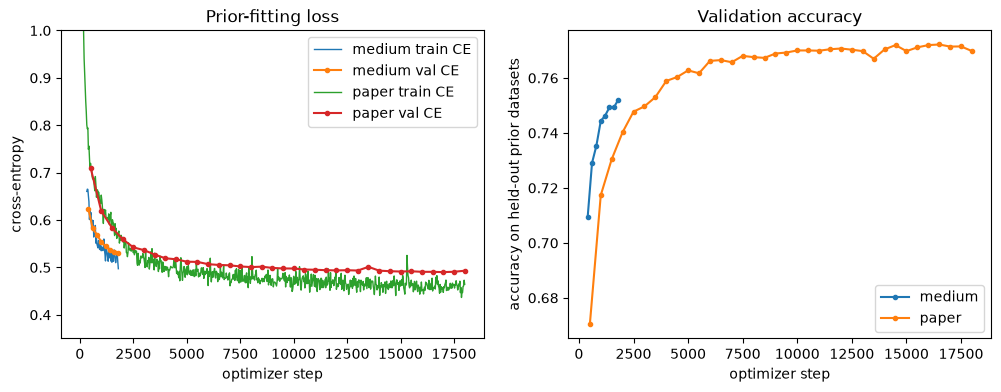

medium: 마지막 val CE 0.530, val acc 0.752
paper: 마지막 val CE 0.493, val acc 0.770


In [9]:
histories = {}
for name, run_id in RUNS.items():
    path = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path="history.json")
    histories[name] = json.loads(open(path).read())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    axes[0].plot(h["step"], h["train_ce"], lw=1, label=f"{name} train CE")
    axes[0].plot(h["val_step"], h["val_ce"], "o-", ms=3, label=f"{name} val CE")
    axes[1].plot(h["val_step"], h["val_acc"], "o-", ms=3, label=name)
axes[0].set_xlabel("optimizer step")
axes[0].set_ylabel("cross-entropy")
axes[0].set_ylim(0.35, 1.0)
axes[0].set_title("Prior-fitting loss")
axes[0].legend()
axes[1].set_xlabel("optimizer step")
axes[1].set_ylabel("accuracy on held-out prior datasets")
axes[1].set_title("Validation accuracy")
axes[1].legend()
plt.show()

for name, h in histories.items():
    print(f"{name}: 마지막 val CE {h['val_ce'][-1]:.3f}, val acc {h['val_acc'][-1]:.3f}")

## 5. Table 1 결과

`eval_tabpfn.py`가 각 run에 남긴 평가 결과(`eval_table1/`)를 불러옵니다. TabPFN은 앙상블 32개와 앙상블 없음(1개) 두 가지로, baseline은 sklearn 기본값 모델 세 개를 같은 split에서 직접 돌렸습니다. 논문의 1시간 튜닝 baseline은 논문 수치를 그대로 옮겼습니다.

In [10]:
def load_eval(run_id, name):
    path = mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path=f"eval_table1/{name}")
    return pd.read_csv(path)


per_dataset = {name: load_eval(run_id, "eval_per_dataset.csv") for name, run_id in RUNS.items()}

rows = []
for method in ["TabPFN", "TabPFN (no ensemble)"]:
    row = {"방법": method}
    for name, df in per_dataset.items():
        row[f"이 구현 ({name})"] = df[df.method == method].roc_auc.mean()
    row["논문 Table 1"] = spec.PAPER_TABLE1_ROC_AUC[method]
    rows.append(row)
for method in [
    "LogisticRegression (default)",
    "HistGradientBoosting (default)",
    "RandomForest (default)",
]:
    rows.append(
        {
            "방법": method,
            "이 구현 (paper)": per_dataset["paper"].query("method == @method").roc_auc.mean(),
        }
    )
for method in ["AutoGluon", "Auto-sklearn 2.0", "XGBoost", "CatBoost", "LightGBM"]:
    rows.append(
        {"방법": f"{method} (논문, 1시간 튜닝)", "논문 Table 1": spec.PAPER_TABLE1_ROC_AUC[method]}
    )
pd.DataFrame(rows).set_index("방법").round(3)

,이 구현 (medium),이 구현 (paper),논문 Table 1
방법,,,
TabPFN,0.924,0.932,0.934
TabPFN (no ensemble),0.913,0.928,0.932
LogisticRegression (default),NaN,0.918,NaN
HistGradientBoosting (default),NaN,0.908,NaN
RandomForest (default),NaN,0.906,NaN
"AutoGluon (논문, 1시간 튜닝)",NaN,NaN,0.930
"Auto-sklearn 2.0 (논문, 1시간 튜닝)",NaN,NaN,0.929
"XGBoost (논문, 1시간 튜닝)",NaN,NaN,0.924
"CatBoost (논문, 1시간 튜닝)",NaN,NaN,0.924


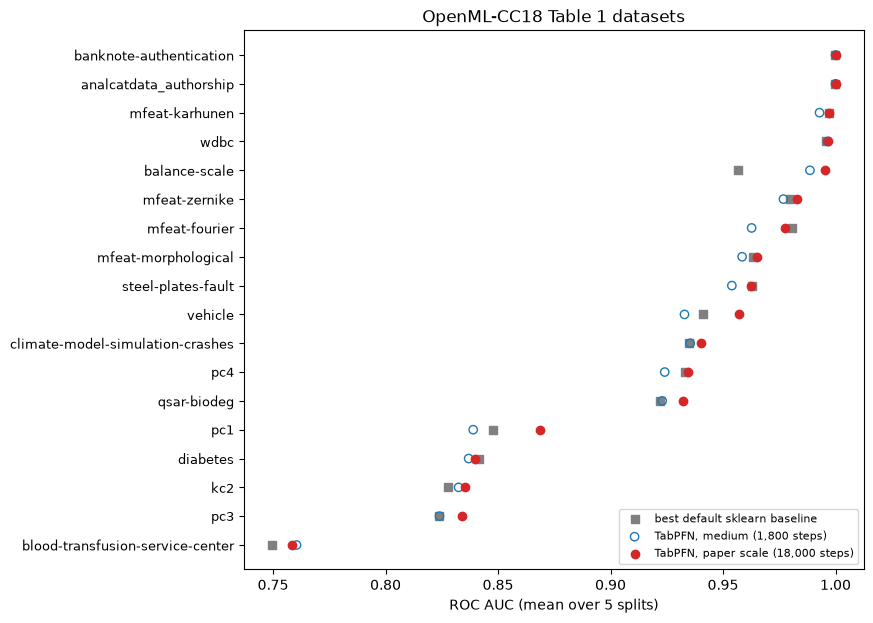

method,TabPFN,TabPFN (no ensemble),TabPFN (medium),best default baseline
dataset,,,,
blood-transfusion-service-center,0.758,0.762,0.760,0.749
pc3,0.834,0.829,0.824,0.824
kc2,0.835,0.832,0.832,0.828
diabetes,0.840,0.839,0.837,0.842
pc1,0.869,0.860,0.839,0.848
qsar-biodeg,0.932,0.932,0.923,0.922
pc4,0.934,0.923,0.924,0.933
climate-model-simulation-crashes,0.940,0.939,0.935,0.935
vehicle,0.957,0.958,0.933,0.941


In [11]:
df = per_dataset["paper"]
wide = df.pivot(index="dataset", columns="method", values="roc_auc")
wide["best default baseline"] = wide[
    ["LogisticRegression (default)", "HistGradientBoosting (default)", "RandomForest (default)"]
].max(axis=1)
medium = per_dataset["medium"].pivot(index="dataset", columns="method", values="roc_auc")
wide["TabPFN (medium)"] = medium["TabPFN"]
wide = wide.sort_values("TabPFN")

fig, ax = plt.subplots(figsize=(8, 7))
ypos = np.arange(len(wide))
ax.scatter(
    wide["best default baseline"],
    ypos,
    marker="s",
    color="gray",
    label="best default sklearn baseline",
)
ax.scatter(
    wide["TabPFN (medium)"],
    ypos,
    marker="o",
    facecolors="none",
    edgecolors="C0",
    label="TabPFN, medium (1,800 steps)",
)
ax.scatter(wide["TabPFN"], ypos, marker="o", color="C3", label="TabPFN, paper scale (18,000 steps)")
ax.set_yticks(ypos)
ax.set_yticklabels(wide.index, fontsize=9)
ax.set_xlabel("ROC AUC (mean over 5 splits)")
ax.set_title("OpenML-CC18 Table 1 datasets")
ax.legend(loc="lower right", fontsize=8)
plt.show()

wide[["TabPFN", "TabPFN (no ensemble)", "TabPFN (medium)", "best default baseline"]].round(3)

논문 규모로 학습한 모델의 평균 ROC AUC는 **0.932**로 논문 0.934와 0.002 차이이고, 앙상블 없이 **0.928**로 논문 0.932와 0.004 차이입니다. 둘 다 기준(0.01 이내) 안이므로 Table 1 재현에 성공했습니다.

같은 split에서 직접 돌린 sklearn 기본값 baseline 중 가장 좋은 LogisticRegression(0.918)보다 0.014 높습니다. 논문이 보고한 1시간 튜닝 AutoGluon(0.930), XGBoost(0.924)와도 비슷하거나 높지만, 이 둘은 같은 split에서 다시 돌린 값이 아니라 논문 수치라서 직접 비교는 아닙니다.

medium(예산 1/10)과 나란히 보면 학습 예산의 효과가 드러납니다. 평균은 0.924에서 0.932로 올랐고, 앙상블 없는 모델은 0.913에서 0.928로 더 크게 올랐습니다. 앙상블을 쓴 모델에서 많이 오른 곳은 pc1(+0.030), vehicle(+0.024), mfeat-fourier(+0.015)입니다. 앙상블 없는 모델에서는 10클래스 mfeat 데이터셋 네 개가 특히 크게 올랐습니다(medium 0.909~0.955 → 0.961~0.992). 앙상블은 클래스 번호를 돌려 가며 평균을 내서 덜 학습된 모델의 약점을 어느 정도 가려 주는데, 학습을 더 하면 앙상블 없이도 클래스가 많은 문제를 잘 맞히게 됩니다.

데이터셋별로는 18개 중 13개에서 가장 좋은 기본값 baseline보다 높고, 2개는 같고(banknote-authentication, analcatdata_authorship 모두 1.000), 3개는 조금 낮습니다(diabetes −0.002, mfeat-fourier −0.003, steel-plates-fault −0.0004).

## 6. 데이터셋 하나로 예측 과정 보기

학습한 모델이 실제로 하는 일을 diabetes 데이터셋(OpenML 37) split 1로 따라가 봅니다. 768행을 반으로 나눠 384행은 정답과 함께 넣고, 나머지 384행의 클래스 확률을 forward pass로 받습니다. 모델을 새로 학습하지 않습니다.

In [12]:
model_path = mlflow.artifacts.download_artifacts(
    run_id=RUNS["paper"], artifact_path="model/tabpfn_final.pt"
)
device = "cuda" if torch.cuda.is_available() else "cpu"
paper_model, _ = load_tabpfn(model_path, map_location=device)

ds = load_openml_dataset(37)
x_tr, y_tr, x_te, y_te = generate_split(ds.x, ds.y, split_number=1)
proba = tabpfn_predict_proba(
    paper_model, x_tr, y_tr, x_te, n_ensemble=spec.N_ENSEMBLE, device=device
)
print(f"학습 행 {len(x_tr)}개, 테스트 행 {len(x_te)}개, ROC AUC {roc_auc(y_te, proba):.3f}")

example = pd.DataFrame(x_te[:5, :3], columns=["x1", "x2", "x3"]).round(1)
example["정답 y"] = y_te[:5]
example["P(y=0)"] = proba[:5, 0].round(3)
example["P(y=1)"] = proba[:5, 1].round(3)
example

학습 행 384개, 테스트 행 384개, ROC AUC 0.819


,x1,x2,x3,정답 y,P(y=0),P(y=1)
0,1.0,100.0,66.0,0,0.871,0.129
1,4.0,189.0,110.0,0,0.132,0.868
2,1.0,90.0,62.0,0,0.928,0.072
3,7.0,181.0,84.0,1,0.087,0.913
4,4.0,127.0,88.0,0,0.807,0.193


## 7. 정리와 한계

| | 논문 | 이 구현 |
|---|---|---|
| Table 1 평균 ROC AUC (앙상블 32) | 0.934 | 0.932 |
| Table 1 평균 ROC AUC (앙상블 없음) | 0.932 | 0.928 |
| 파라미터 수 | 25.82M | 25,821,706 |
| 학습 | 18,000 step × batch 512, RTX 2080 Ti 8장 20시간 | 18,000 step × batch 512, H100 8장 2시간 5분 |
| prior | SCM + BNN (+ GP), 하이퍼파라미터도 분포에서 뽑음 | v1 코드를 torch로 옮긴 것 (`src/minipfn/tabpfn/prior.py`) |

논문 수치(모델 크기, batch, step, prior 분포, 평가 프로토콜)를 그대로 쓰면 논문 Table 1의 결과가 0.01 안쪽으로 다시 나옵니다. 데이터셋마다 모델을 학습하지 않고, 학습 행을 문맥으로 넣는 forward pass만으로 기본값 baseline보다 좋은 예측을 한다는 논문의 주장도 같은 split에서 확인했습니다.

한계도 있습니다.

- **공식 체크포인트와 직접 비교하지 않았습니다.** v1 저장소의 공개 가중치는 외부 pickle 파일이라 이 작업 환경에서 열지 않았습니다. 그래서 "공식 모델과 같은 split에서 같은 점수"는 확인하지 못했고, 논문에 적힌 평균값과만 비교했습니다.
- **18개 데이터셋, split 5개입니다.** 논문 Table 1이 TabPFN 평균에 붙인 ± 값이 약 0.009라서, 0.002~0.004 차이는 그 범위 안입니다. 반대로 말하면 이 실험으로 이보다 작은 차이를 구별하기는 어렵습니다.
- **Table 2(범주형·결측값이 있는 30개 데이터셋)는 재현하지 않았습니다.** 공개 체크포인트처럼 결측값 주입을 끄고 학습했고, 평가 코드도 Table 1 조건만 다룹니다.
- **baseline은 sklearn 기본값입니다.** 논문의 1시간 튜닝 baseline(AutoGluon, XGBoost 등)은 직접 돌리지 않고 논문 수치를 인용했습니다.